# Bangla Multimodal Fake News: Model Selection (03)

This notebook runs the full model-selection grid and prints every result.

**What it does, in order**
1. Mounts Drive and unpacks the project code.
2. Extracts frozen backbone features that do not exist yet (mBERT, XLM-R, ViT, Swin).
3. Trains every configuration with 3 seeds: 3 text, 3 image, 2 controls and 27 fusion combinations.
4. Prints accuracy, macro-precision, macro-recall and macro-F1 for every configuration, plus the confusion matrix and per-class F1.
5. Picks the winners by **validation** macro-F1 only. The test set is printed but never used for a choice.

**Runtime:** GPU (T4). Run the cells in order. Results are saved to Drive, so a disconnect does not lose finished work.

## 0. Check the GPU

In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


## 1. Mount Drive and unpack the project code

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import os
import shutil
import zipfile
from pathlib import Path

ZIP = Path("/content/drive/MyDrive/Bangla-Multimodal-FakeNews.zip")
CODE_DIR = Path("/content/Bangla-Multimodal-FakeNews")
assert ZIP.exists(), "Code zip not found in MyDrive. Upload the latest zip first."

shutil.rmtree(CODE_DIR, ignore_errors=True)
with zipfile.ZipFile(ZIP) as z:
    z.extractall("/content")
os.chdir(CODE_DIR)
print("cwd:", os.getcwd())
config_text = Path("configs/config.py").read_text(encoding="utf-8")
assert "TEXT_BACKBONES" in config_text and "LOCAL_LLM_MODEL" in config_text, "Old code. Upload the latest zip."
print("Code version OK")

cwd: /content/Bangla-Multimodal-FakeNews
Code version OK


## 2. Install packages

In [4]:
!pip install -q "accelerate>=0.26" "transformers>=4.46" "sentence-transformers>=3.0" "rank-bm25>=0.2.2" joblib openpyxl

## 3. Check the inputs

These files come from notebook 02 (features) and script 01 (data). Missing files stop the notebook here.

In [5]:
from configs.config import FEATURE_DIR, PROCESSED_DIR
import numpy as np
import pandas as pd

required = ["meta.csv", "bert.npy", "clip_img.npy"]
for name in required:
    assert (FEATURE_DIR / name).exists(), f"missing {name}: run notebook 02 first"
assert (PROCESSED_DIR / "unified_split.csv").exists(), "missing unified_split.csv: run script 01 first"

meta = pd.read_csv(FEATURE_DIR / "meta.csv")
print(meta["split"].value_counts().to_string())
print("rows with image:", int(meta["has_image"].sum()), "of", len(meta))
for name in ["bert", "clip_img"]:
    print(name, np.load(FEATURE_DIR / f"{name}.npy").shape)

split
train    2736
test      588
val       586
rows with image: 2397 of 3910
bert (3910, 768)
clip_img (3910, 512)


## 4. Extract the missing backbone features

Only missing features are computed. BanglaBERT and CLIP reuse the existing files.

In [6]:
!python scripts/07_extract_backbones.py

[REUSE] text banglabert: bert.npy (3910, 768)
[REUSE] text mbert: text_mbert.npy (3910, 768)
[REUSE] text xlmr: text_xlmr.npy (3910, 768)
[REUSE] image clip: clip_img.npy (3910, 512)
        zero rows == rows without image: True (1513 zero rows)
[REUSE] image vit: img_vit.npy (3910, 768)
        zero rows == rows without image: True (1513 zero rows)
[REUSE] image swin: img_swin.npy (3910, 768)
        zero rows == rows without image: True (1513 zero rows)


## 5. Train the whole grid

The grid has 35 configurations (3 text, 3 image, 2 controls, 27 fusion) x 3 seeds = 105 runs.
The script prints the run count first, then one line per run with its validation and test macro-F1.

In [7]:
!python scripts/08_model_selection.py

Configurations: 35 x seeds [42, 43, 44] = 105 runs
[  1/105] text:banglabert                          seed 42: val F1 0.6908 | test F1 0.5880 acc 0.7568
[  2/105] text:banglabert                          seed 43: val F1 0.6983 | test F1 0.6463 acc 0.7789
[  3/105] text:banglabert                          seed 44: val F1 0.6860 | test F1 0.6471 acc 0.7874
[  4/105] text:mbert                               seed 42: val F1 0.6346 | test F1 0.5971 acc 0.6956
[  5/105] text:mbert                               seed 43: val F1 0.6388 | test F1 0.6273 acc 0.7279
[  6/105] text:mbert                               seed 44: val F1 0.6271 | test F1 0.6427 acc 0.7415
[  7/105] text:xlmr                                seed 42: val F1 0.6935 | test F1 0.6312 acc 0.7381
[  8/105] text:xlmr                                seed 43: val F1 0.6890 | test F1 0.6723 acc 0.7585
[  9/105] text:xlmr                                seed 44: val F1 0.6962 | test F1 0.6295 acc 0.7449
[ 10/105] image:clip           

## 6. Results for every configuration (mean ± std over 3 seeds)

In [8]:
import json
from configs.config import SELECTION_DIR
from src.selection import format_table

summary = json.loads((SELECTION_DIR / "summary.json").read_text(encoding="utf-8"))
cols = [
    ("val_macro_f1", "Val F1"),
    ("test_accuracy", "Test Acc"),
    ("test_macro_precision", "Test Prec"),
    ("test_macro_recall", "Test Recall"),
    ("test_macro_f1", "Test F1"),
]
for kind, title in [("text", "TEXT ONLY"), ("image", "IMAGE ONLY"),
                    ("control", "CONTROLS (not eligible)"), ("fusion", "FUSION (all combinations)")]:
    names = sorted([n for n, r in summary.items() if r["kind"] == kind],
                   key=lambda n: -summary[n]["val_macro_f1_mean"])
    print("=" * 110)
    print(title)
    print(format_table(summary, names, cols))
    print()

TEXT ONLY
config                                                Val F1          Test Acc         Test Prec       Test Recall           Test F1
------------------------------------------------------------------------------------------------------------------------------------
text:xlmr                                     0.6929+-0.0030    0.7472+-0.0085    0.6501+-0.0209    0.6408+-0.0197    0.6443+-0.0198
text:banglabert                               0.6917+-0.0050    0.7744+-0.0129    0.6278+-0.0244    0.6295+-0.0276    0.6271+-0.0277
text:mbert                                    0.6335+-0.0048    0.7217+-0.0193    0.6309+-0.0329    0.6191+-0.0069    0.6224+-0.0190

IMAGE ONLY
config                                                Val F1          Test Acc         Test Prec       Test Recall           Test F1
------------------------------------------------------------------------------------------------------------------------------------
image:clip                                    0

## 7. Confusion matrix and per-class F1 for every configuration

Matrices are test-set counts averaged over the 3 seeds. Rows are the true class, columns the prediction.

In [9]:
from configs.config import LABELS_3
from src.selection import confusion_text

runs = json.loads((SELECTION_DIR / "runs.json").read_text(encoding="utf-8"))
ordered = sorted(summary, key=lambda n: (summary[n]["kind"], -summary[n]["val_macro_f1_mean"]))
for name in ordered:
    r = summary[name]
    per = {lab: [] for lab in LABELS_3}
    for rec in runs:
        if rec["name"] == name:
            for lab in LABELS_3:
                per[lab].append(rec["details"]["test"]["per_class"][lab]["f1"])
    print("=" * 80)
    print(f"{name}   [{r['kind']}]")
    print(f"  Val F1 {r['val_macro_f1_mean']:.4f}  | Test acc {r['test_accuracy_mean']:.4f}  "
          f"| Test F1 {r['test_macro_f1_mean']:.4f}")
    print("  Per-class test F1: " + ", ".join(f"{lab} {np.mean(per[lab]):.3f}" for lab in LABELS_3))
    print(confusion_text(np.array(r["test_confusion_mean"]), LABELS_3))
    print()

control:length_only   [control]
  Val F1 0.4523  | Test acc 0.5703  | Test F1 0.4647
  Per-class test F1: Authentic 0.713, Misleading 0.523, Satire 0.158
true \ pred    Authentic  Misleading      Satire
Authentic            215        58.7        63.3
Misleading          48.3         106        64.7
Satire               2.7          15        14.3

control:has_image_only   [control]
  Val F1 0.1789  | Test acc 0.2245  | Test F1 0.2023
  Per-class test F1: Authentic 0.000, Misleading 0.463, Satire 0.144
true \ pred    Authentic  Misleading      Satire
Authentic              0         122         215
Misleading             0         104         115
Satire                 0           4          28

fusion:early:banglabert+clip   [fusion]
  Val F1 0.7446  | Test acc 0.8220  | Test F1 0.7279
  Per-class test F1: Authentic 0.870, Misleading 0.787, Satire 0.527
true \ pred    Authentic  Misleading      Satire
Authentic            288        46.3         2.7
Misleading          33.3       181.

## 8. Winners (chosen on validation only)

In [10]:
best = json.loads((SELECTION_DIR / "best_config.json").read_text(encoding="utf-8"))
print("Rule:", best["rule"])
for stage in ["text", "image", "fusion"]:
    name = best[stage]
    r = summary[name]
    print(f"{stage:>7}: {name:<40} Val F1 {r['val_macro_f1_mean']:.4f} +- {r['val_macro_f1_std']:.4f} | "
          f"Test F1 {r['test_macro_f1_mean']:.4f} | Test acc {r['test_accuracy_mean']:.4f}")

Rule: highest mean validation macro-F1 over seeds; ties go to smaller std; test never used
   text: text:xlmr                                Val F1 0.6929 +- 0.0030 | Test F1 0.6443 | Test acc 0.7472
  image: image:clip                               Val F1 0.5656 +- 0.0018 | Test F1 0.5413 | Test acc 0.6009
 fusion: fusion:early:banglabert+clip             Val F1 0.7446 +- 0.0130 | Test F1 0.7279 | Test acc 0.8220


## 9. Plots: validation F1 of the fusion grid, and confusion matrices of the winners

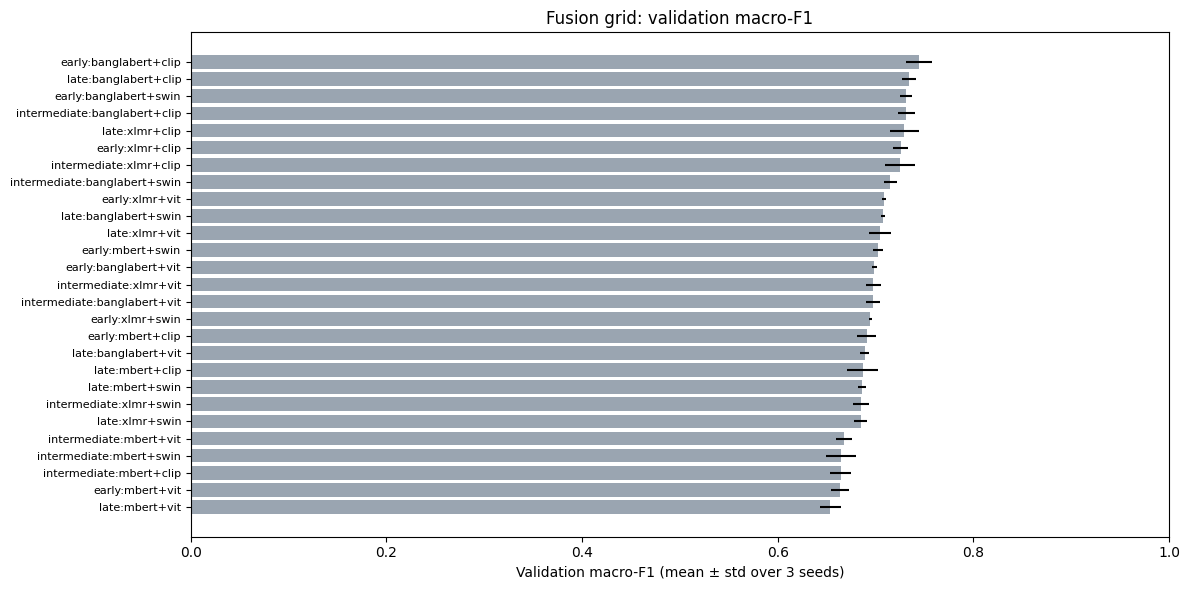

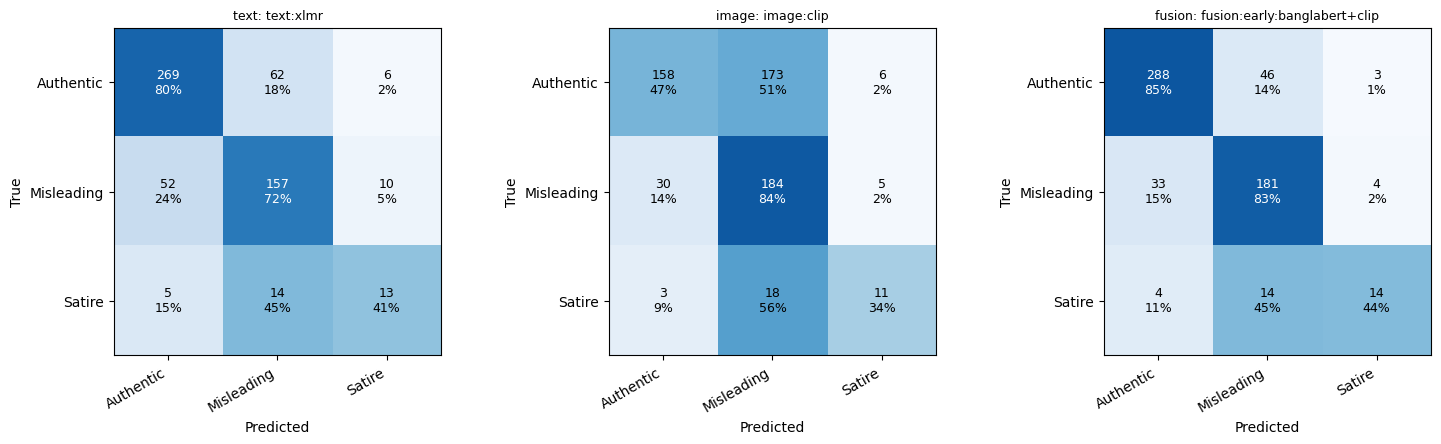

In [11]:
import matplotlib.pyplot as plt

fusion_names = sorted([n for n, r in summary.items() if r["kind"] == "fusion"],
                      key=lambda n: -summary[n]["val_macro_f1_mean"])
vals = [summary[n]["val_macro_f1_mean"] for n in fusion_names]
errs = [summary[n]["val_macro_f1_std"] for n in fusion_names]
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(range(len(fusion_names)), vals, xerr=errs, color="#9aa5b1")
ax.set_yticks(range(len(fusion_names)), [n.replace("fusion:", "") for n in fusion_names], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Validation macro-F1 (mean ± std over 3 seeds)")
ax.set_title("Fusion grid: validation macro-F1")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, stage in zip(axes, ["text", "image", "fusion"]):
    name = best[stage]
    cm = np.array(summary[name]["test_confusion_mean"])
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.0f}\n{row_pct[i, j]:.0%}", ha="center", va="center",
                    color="white" if row_pct[i, j] > 0.6 else "black", fontsize=9)
    ax.set_xticks(range(3), LABELS_3, rotation=30, ha="right")
    ax.set_yticks(range(3), LABELS_3)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{stage}: {name}", fontsize=9)
plt.tight_layout()
plt.show()

## 10. Saved files

- `results/selection/summary.md`: all tables
- `results/selection/runs.json`: every run with its metrics and confusion matrices
- `results/selection/best_config.json`: the winners
- `checkpoints/selection/`: head weights (float16), for the app

In [12]:
from configs.config import RESULTS_DIR, CHECKPOINT_DIR
for p in sorted((RESULTS_DIR / "selection").glob("*.*")) + [CHECKPOINT_DIR / "selection"]:
    if p.is_file():
        print(f"{p.name:<30} {p.stat().st_size / 1e6:8.2f} MB")
print("checkpoint files:", len(list((CHECKPOINT_DIR / "selection").glob("*.pt"))))

best_config.json                   0.00 MB
runs.json                          0.31 MB
summary.json                       0.04 MB
summary.md                         0.01 MB
checkpoint files: 132


## Next step (not run yet)

Evidence (E5) and cultural (E4) are added on top of the winning fusion, one at a time, with the same validation rule. That needs `scripts/05` (cultural labels) and `scripts/06` (Wikipedia evidence) to finish first, and their quality checks to pass.